# KV Cache and Grouped-Query Attention (GQA)

---

Creator: Chung-En Johnny Yu

Content updated: 2026-10-29

Hands-on practice this notebook on your Google Colab:
1. [Click here to open this notebook](https://colab.research.google.com/github/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/03_gqa_kv_cache.ipynb)
2. Now, run the code and practice it!

Extends `02_attention.ipynb` and `03_architecture_gpt.ipynb` to inference. Prerequisite: `02_self_and_cross_attention`. The question: *why does generating text cost something different from training, and how do modern LLMs make it cheaper?*

**Sources** — sections taken from Raschka are tagged; everything else is written for this notebook:

| Tag | Source |
|---|---|
| 📗 **[KV-cache bonus]** | Sebastian Raschka, LLMs-from-scratch [`ch04/03_kv-cache`](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch04/03_kv-cache) — README text, `gpt_ch04.py`, `gpt_with_kv_cache.py` |
| 📗 **[GQA bonus]** | Raschka, [`ch04/04_gqa`](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch04/04_gqa) — README text, `gpt_with_kv_gqa.py`, `memory_estimator_gqa.py` |
| 📗 **figures** | from the two bonus folders above |

CPU only; about one minute (an untrained GPT-2-sized model generates 200 tokens twice). No weights are downloaded.

| Part | Content |
|---|---|
| 1 | How a KV cache works |
| 2 | Raschka's implementation, and the "same output" test |
| 3 | Trade-offs: compute vs memory, prefill vs decode |
| 4 | Grouped-query attention |
| 5 | How much memory? Estimator, calculator and an 8B worked example |
| 6 | Interview-style check questions |

---

In [1]:
import inspect, math, os, subprocess, sys, time, urllib.request
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
try:
    import tiktoken
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tiktoken"])
    import tiktoken

# fetch Raschka's scripts: local copy -> this repo -> original repo
SCRIPTS = {"gpt_ch04.py": "ch04/03_kv-cache", "gpt_with_kv_cache.py": "ch04/03_kv-cache",
           "gpt_with_kv_gqa.py": "ch04/04_gqa", "memory_estimator_gqa.py": "ch04/04_gqa"}
local_dir = os.path.join("03-gqa_kv_cache", "data")
if os.path.isdir(local_dir):
    sys.path.insert(0, local_dir); SCRIPT_DIR = local_dir
else:
    SCRIPT_DIR = "."
    for name, folder in SCRIPTS.items():
        if os.path.exists(name):
            continue
        for url in [f"https://raw.githubusercontent.com/chungenyu6/ai-learning-notebooks/main/02-LLM/live/03-gqa_kv_cache/data/{name}",
                    f"https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/{folder}/{name}"]:
            try:
                urllib.request.urlretrieve(url, name); break
            except Exception as e:
                print("could not download", url, e)

import gpt_ch04, gpt_with_kv_cache, gpt_with_kv_gqa
print("torch", torch.__version__, "| scripts from", SCRIPT_DIR)

torch 2.13.0 | scripts from 03-gqa_kv_cache/data


## 1. How a KV cache works

📗 *[KV-cache bonus] text and figures*

Generation has two phases. **Prefill** processes the whole prompt in one parallel pass, like training. **Decode** then produces one token at a time, and each new token's query must attend to the keys and values of every previous token.

📗 In short, a KV cache stores intermediate key (K) and value (V) computations for reuse during inference, which results in a substantial speed-up when generating responses. The downside is that it adds some complexity to the code, increases memory usage, and can't be used during training.

Imagine the LLM is given the prompt "Time flies". The figure below shows an excerpt of the attention score computation with the key and value vectors highlighted:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/03-gqa_kv_cache/img/kv-cache-attn-1.png?raw=true" width="450px">

*Figure: attention for "Time flies", keys and values highlighted. Source: Raschka, LLMs-from-scratch, KV-cache bonus (original image `bonus/kv-cache/kv-cache-attn-1.png`).*

Suppose the LLM generated the word "fast", so the prompt for the next round becomes "Time flies fast":

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/03-gqa_kv_cache/img/kv-cache-attn-2.png?raw=true" width="600px">

*Figure: the keys and values of "Time" and "flies" are recomputed unchanged — wasted work. Source: Raschka, LLMs-from-scratch, KV-cache bonus (original image `bonus/kv-cache/kv-cache-attn-2.png`).*

The key and value vectors for the first two tokens are exactly the same, so recomputing them in every generation round is wasteful. The KV cache stores previously computed keys and values for reuse.

Note what is cached: **K and V, not Q**. Past queries are never needed again, because a past token's output has already been produced.

## 2. The implementation

📗 *[KV-cache bonus] text and code*

The bonus folder contains two self-contained scripts: `gpt_ch04.py` (the GPT model from Chapters 3–4) and `gpt_with_kv_cache.py` (the same model with a KV cache; changes are marked `# NEW`). The changes, in short:

1. **Register the cache buffers** `cache_k` and `cache_v` inside `MultiHeadAttention`.
2. **`forward(x, use_cache=False)`**: project only the new tokens into `keys_new`, `values_new`, `queries`; then either initialize the cache or append to it with `torch.cat`, and slice the causal mask using a position pointer `ptr_current_pos`.
3. **`reset_cache()`** clears the buffers between independent generations.
4. **Propagate `use_cache`** through `TransformerBlock` and `GPTModel`, which also tracks `current_pos` so positional embeddings use the right absolute positions.
5. **Generation** feeds the whole prompt once, then only the newly generated token.

Here is the attention `forward` from `gpt_with_kv_cache.py`:

In [2]:
# Source: Raschka, LLMs-from-scratch, ch04/03_kv-cache/gpt_with_kv_cache.py
print(inspect.getsource(gpt_with_kv_cache.MultiHeadAttention.forward))

    def forward(self, x, use_cache=False):
        b, num_tokens, d_in = x.shape

        keys_new = self.W_key(x)  # Shape: (b, num_tokens, d_out)
        values_new = self.W_value(x)
        queries = self.W_query(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys_new = keys_new.view(b, num_tokens, self.num_heads, self.head_dim)
        values_new = values_new.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        ####################################################
        # NEW
        if use_cache:
            if self.cache_k is None:
                self.cache_k, self.cache_v = keys_new, values_new
            else:
                self.cache_k = torch.cat([self.cache_k, keys_new], dim=1)
                self.cache_v = torch.cat([self.cache_v, values_new], dim=1)
       

And the cached generation loop:

In [3]:
# Source: Raschka, LLMs-from-scratch, ch04/03_kv-cache/gpt_with_kv_cache.py
print(inspect.getsource(gpt_with_kv_cache.generate_text_simple_cached))

def generate_text_simple_cached(model, idx, max_new_tokens,
                                context_size=None, use_cache=True):
    model.eval()
    ctx_len = context_size or model.pos_emb.num_embeddings

    with torch.no_grad():
        if use_cache:
            # Init cache with full prompt
            model.reset_kv_cache()
            logits = model(idx[:, -ctx_len:], use_cache=True)

            for step in range(max_new_tokens):
                # a) pick the token with the highest log-probability (greedy sampling)
                next_idx = logits[:, -1].argmax(dim=-1, keepdim=True)
                # b) append it to the running sequence
                idx = torch.cat([idx, next_idx], dim=1)
                # c) feed model only the new token
                if step + 1 < max_new_tokens:  # Skips the forward pass after the last token is generated
                    logits = model(next_idx, use_cache=True)
        else:
            for _ in range(max_new_tokens):
                

### Same text, faster

📗 The bonus runs an **untrained** 124M-parameter GPT to generate 200 new tokens from "Hello, I am" with and without the cache. The text is gibberish because the model is untrained — what matters is that **both versions produce exactly the same tokens**, which tells us the cache is implemented correctly (it is easy to make indexing mistakes that lead to divergent results). On an M4 Mac Mini CPU the bonus reports 27 vs 144 tokens/sec (~5× speed-up).

In [4]:
# Source: adapted from Raschka, gpt_ch04.py / gpt_with_kv_cache.py main(); assert added
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
}
tokenizer = tiktoken.get_encoding("gpt2")
encoded_tensor = torch.tensor(tokenizer.encode("Hello, I am")).unsqueeze(0)

torch.manual_seed(123)
model_plain = gpt_ch04.GPTModel(GPT_CONFIG_124M).eval()
torch.manual_seed(123)
model_cached = gpt_with_kv_cache.GPTModel(GPT_CONFIG_124M).eval()
model_cached.load_state_dict(model_plain.state_dict())            # guarantee identical weights

results = {}
for name, fn in [("no cache", lambda: gpt_ch04.generate_text_simple(model_plain, encoded_tensor, 200, GPT_CONFIG_124M["context_length"])),
                 ("KV cache", lambda: gpt_with_kv_cache.generate_text_simple_cached(model_cached, encoded_tensor, 200))]:
    t0 = time.time()
    results[name] = fn()
    dt = time.time() - t0
    print(f"{name:9s}: {dt:5.1f} s  ->  {int(results[name].shape[1] / dt)} tokens/sec")

assert torch.equal(results["no cache"], results["KV cache"])
print("identical token ids with and without the cache ✓")
print("Output text:", tokenizer.decode(results["KV cache"][0].tolist())[:120], "...")

no cache :  20.3 s  ->  10 tokens/sec


KV cache :   6.4 s  ->  31 tokens/sec
identical token ids with and without the cache ✓
Output text: Hello, I am Featureiman Byeswickattribute argue logger Normandy Compton analogous bore ITVEGIN ministriesysics Kle funct ...


## 3. Trade-offs

📗 *[KV-cache bonus] text*

- **[Good] Computational efficiency increases.** Without caching, the attention at step $t$ must compare the new query with $t$ previous keys *and* recompute every key and value, so the cumulative work scales quadratically, $O(n^2)$. With a cache, each key and value is computed once and reused.
- **[Bad] Memory usage increases linearly.** Each new token appends to the cache; for long sequences and larger LLMs it can consume a significant or even prohibitive amount of GPU memory.
- **Production implementations** pre-allocate the cache tensors for the maximum sequence length instead of repeatedly calling `torch.cat` (which causes reallocation and fragmentation); serving engines such as vLLM go further with paged allocation.

**Prefill is compute-bound, decode is memory-bandwidth-bound.** Prefill processes many tokens per weight load (matrix–matrix products). Each decode step processes one token per sequence but must stream *all* weights and the *whole* KV cache from GPU memory (matrix–vector products), so it does little arithmetic per byte. Shrinking the cache therefore makes decoding **faster**, not just cheaper — which is exactly what GQA does.

## 4. Grouped-query attention

📗 *[GQA bonus] text, figure and code*

Grouped-Query Attention (GQA) has become the standard, more compute- and parameter-efficient replacement for Multi-Head Attention (MHA). It goes back to [Ainslie et al. (2023)](https://arxiv.org/abs/2305.13245), and even the larger Llama 2 models used it.

Unlike MHA, where each head has its own keys and values, GQA groups multiple query heads to share the same key and value projections. With 3 key-value groups and 6 attention heads, heads 1–2 share one set of keys and values, heads 3–4 another, and heads 5–6 a third:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/03-gqa_kv_cache/img/gqa-1.webp?raw=true" width="600px">

*Figure: MHA vs GQA with `group_size = n_heads / n_kv_groups = 2`. Source: Raschka, LLMs-from-scratch, GQA bonus (original image `bonus/gqa-memory/1.webp`).*

This (1) lowers the parameter count and (2) reduces the memory and memory bandwidth for the KV cache, since fewer keys and values are stored and retrieved. Ablations in the GQA and Llama 2 papers show it performs comparably to MHA — if the number of groups is chosen carefully. With a **single** group (**multi-query attention**, MQA) memory drops even more but quality can suffer; with as many groups as heads we are back to MHA.

The number of **query** heads never changes — GQA is not "fewer queries". Here is the bonus implementation (it also contains the KV cache from Part 2):

In [5]:
# Source: Raschka, LLMs-from-scratch, ch04/04_gqa/gpt_with_kv_gqa.py
GroupedQueryAttention = gpt_with_kv_gqa.GroupedQueryAttention
print(inspect.getsource(GroupedQueryAttention.__init__))
print(inspect.getsource(GroupedQueryAttention.forward).split("# Compute scaled dot-product")[0])

    def __init__(
            self, d_in, d_out, dropout, num_heads, num_kv_groups, dtype=None, qkv_bias=False
    ):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"
        assert num_heads % num_kv_groups == 0, "num_heads must be divisible by num_kv_groups"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads

        self.W_key = nn.Linear(d_in, num_kv_groups * self.head_dim, bias=qkv_bias, dtype=dtype)
        self.W_value = nn.Linear(d_in, num_kv_groups * self.head_dim, bias=qkv_bias, dtype=dtype)
        self.num_kv_groups = num_kv_groups
        self.group_size = num_heads // num_kv_groups

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias, dtype=dtype)
        self.out_proj = nn.Linear(d_out, d_out, bias=False, dtype=dtype)
        self.dropout = nn.Dropout(dropout)

        self.register_buffer("cache_k", None, persistent=False)
        self.register_buffer("

**Tests.** For MHA ($H_{kv}=H$), GQA and MQA ($H_{kv}=1$): (a) running a prompt plus token-by-token cached decoding must equal one full causal pass — the single most important test for any cache; (b) the cache and $W_K, W_V$ shrink by $H/H_{kv}$.

In [6]:
torch.manual_seed(0)
d_model, H = 64, 8
x = torch.randn(2, 12, d_model)

for n_kv in (8, 2, 1):                                     # MHA, GQA, MQA
    gqa = GroupedQueryAttention(d_model, d_model, dropout=0.0, num_heads=H, num_kv_groups=n_kv).eval()
    full = gqa(x)                                          # one causal pass, no cache
    gqa.reset_cache()
    outs = [gqa(x[:, :5], use_cache=True)]                 # prefill 5 prompt tokens
    for t in range(5, 12):                                 # decode 7 tokens one by one
        outs.append(gqa(x[:, t:t + 1], use_cache=True))
    assert torch.allclose(full, torch.cat(outs, dim=1), atol=1e-5)
    kv_params = gqa.W_key.weight.numel() + gqa.W_value.weight.numel()
    print(f"H_kv={n_kv}: cached decode == full pass ✓   cache_k {tuple(gqa.cache_k.shape)}   W_k+W_v params {kv_params}")

H_kv=8: cached decode == full pass ✓   cache_k (2, 8, 12, 8)   W_k+W_v params 8192
H_kv=2: cached decode == full pass ✓   cache_k (2, 2, 12, 8)   W_k+W_v params 2048
H_kv=1: cached decode == full pass ✓   cache_k (2, 1, 12, 8)   W_k+W_v params 1024


The cache shape is `(batch, H_kv, tokens, head_dim)`: 4× smaller with $H_{kv}=2$, 8× smaller with MQA. An existing MHA checkpoint can be converted ("uptrained") to GQA by **mean-pooling** the K/V heads within each group and continuing pretraining for a small fraction (~5%) of the original compute.

## 5. How much memory?

📗 *[GQA bonus] formula, script and figure*

The savings are mostly in the KV storage:

`bytes ≈ batch_size × seqlen × (embed_dim / n_heads) × n_layers × 2 (K,V) × bytes_per_elem × n_kv_heads`

The bonus's estimator, run with its example (a Llama-2-7B-like shape with 32k context; 4 KV groups → 8 KV heads):

In [7]:
# Source: Raschka, LLMs-from-scratch, ch04/04_gqa/memory_estimator_gqa.py
out = subprocess.run([sys.executable, os.path.join(SCRIPT_DIR, "memory_estimator_gqa.py"),
                      "--emb_dim", "4096", "--n_heads", "32", "--n_layers", "32",
                      "--context_length", "32768", "--n_kv_groups", "4",
                      "--batch_size", "1", "--dtype", "bf16"], capture_output=True, text=True)
print(out.stdout or out.stderr)

==== Config ====
context_length   : 32768
emb_dim          : 4096
n_heads          : 32
n_layers         : 32
n_kv_groups      : 4
batch_size       : 1
dtype            : bf16 (2 Bytes/elem)
head_dim         : 128
GQA n_kv_heads   : 8

==== KV-cache totals across all layers ====
MHA total KV cache  : 17.18 GB
GQA total KV cache  : 4.29 GB
Ratio (MHA / GQA)   : 4.00x
Savings (GQA vs MHA): 75.00%



The savings grow with context length:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/03-gqa_kv_cache/img/gqa-3.webp?raw=true" width="500px">

*Figure: total KV cache vs context length for MHA and several GQA group counts. Source: Raschka, LLMs-from-scratch, GQA bonus (original image `bonus/gqa-memory/3.webp`).*

The script reports decimal **GB** ($10^9$ bytes); GPU memory is usually quoted in **GiB** ($2^{30}$), so 17.18 GB = 16 GiB. Below, everything is in GiB, and we add the model weights to answer a typical capacity question:

$$
M_{\text{weights}}\approx P\,b_w,\qquad
M_{\text{KV}} = 2\cdot B\cdot T\cdot L\cdot H_{kv}\cdot d_h\cdot b_{kv},\qquad
M_{\text{required}} > M_{\text{weights}}+M_{\text{KV}} .
$$

The strict "$>$" leaves room for activations, prefill temporaries, the CUDA context and fragmentation: **the formula is a lower bound, never a guarantee that something fits.**

In [8]:
GiB = 2**30
def weights_gib(n_params, bytes_per_weight=2):
    return n_params * bytes_per_weight / GiB

def kv_gib(batch, tokens, layers, kv_heads, head_dim, bytes_per_elem=2):
    return 2 * batch * tokens * layers * kv_heads * head_dim * bytes_per_elem / GiB

# Llama-3-8B-style configuration: 32 layers, 32 query heads, head_dim 128 (d_model 4096), 8 KV heads.
L_, dh_ = 32, 128
for name, H_kv in [("MHA", 32), ("GQA", 8), ("MQA", 1)]:
    print(f"{name} (H_kv={H_kv:2d}): KV cache, batch 1, 8k tokens, BF16 = {kv_gib(1, 8192, L_, H_kv, dh_):.3f} GiB")

MHA (H_kv=32): KV cache, batch 1, 8k tokens, BF16 = 4.000 GiB
GQA (H_kv= 8): KV cache, batch 1, 8k tokens, BF16 = 1.000 GiB
MQA (H_kv= 1): KV cache, batch 1, 8k tokens, BF16 = 0.125 GiB


> *"Can an 8B model in BF16 with an 8k context run on a 16 GiB GPU?"*

weights (≈8B params, BF16)    14.9 GiB
KV cache (GQA, B=1, T=8k)      1.0 GiB
lower bound                   15.9 GiB  (+ runtime buffers, not counted)
  16 GiB GPU -> theoretical headroom   0.1 GiB
  24 GiB GPU -> theoretical headroom   8.1 GiB
  80 GiB GPU -> theoretical headroom  64.1 GiB

B=4 concurrent requests: KV cache 4.0 GiB
4-bit weights, theoretical floor: 3.73 GiB (+ scales/metadata in practice)


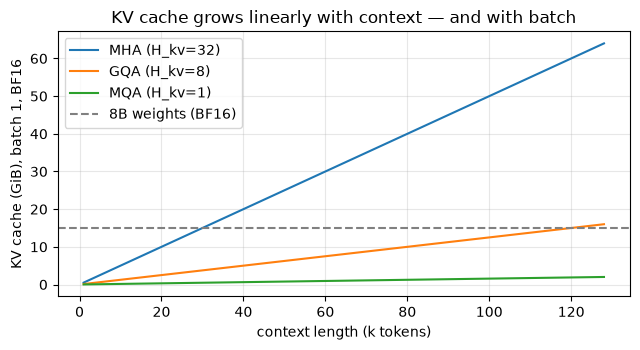

In [9]:
w = weights_gib(8e9, 2)
kv = kv_gib(1, 8192, L_, 8, dh_)
print(f"weights (≈8B params, BF16)   {w:5.1f} GiB")
print(f"KV cache (GQA, B=1, T=8k)    {kv:5.1f} GiB")
print(f"lower bound                  {w + kv:5.1f} GiB  (+ runtime buffers, not counted)")
for gpu in (16, 24, 80):
    print(f"  {gpu:2d} GiB GPU -> theoretical headroom {gpu - (w + kv):5.1f} GiB")
print(f"\nB=4 concurrent requests: KV cache {kv_gib(4, 8192, L_, 8, dh_):.1f} GiB")
print(f"4-bit weights, theoretical floor: {weights_gib(8e9, 0.5):.2f} GiB (+ scales/metadata in practice)")

Ts = torch.arange(1024, 131072 + 1, 1024)
plt.figure(figsize=(6.5, 3.6))
for name, H_kv in [("MHA (H_kv=32)", 32), ("GQA (H_kv=8)", 8), ("MQA (H_kv=1)", 1)]:
    plt.plot(Ts / 1024, [kv_gib(1, int(t), L_, H_kv, dh_) for t in Ts], label=name)
plt.axhline(weights_gib(8e9), color="gray", ls="--", label="8B weights (BF16)")
plt.xlabel("context length (k tokens)"); plt.ylabel("KV cache (GiB), batch 1, BF16")
plt.title("KV cache grows linearly with context — and with batch")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

How to answer the capacity question:

1. **Weights** ≈ 14.9 GiB; **KV cache** (GQA, batch 1, 8k) = 1 GiB; lower bound ≈ 15.9 GiB.
2. A 16 GiB card has ~0.1 GiB left → **do not claim it fits**. A 24 GiB card has ~8 GiB of theoretical headroom; still verify with the actual serving engine.
3. Levers: quantize weights (4-bit ≈ 3.7 GiB floor); quantize the KV cache (FP8 halves it — it does **not** shrink automatically when you quantize weights); shorter context; fewer concurrent sequences; shard across GPUs (needs engine support, adds communication).
4. Host RAM and GPU VRAM are separate budgets; CPU offloading costs PCIe transfer time every forward pass.
5. MoE models: weight memory uses the **total** parameter count (see `05_gpt_vs_llama_vs_moe`).

At 128k context the MHA cache (64 GiB) is ~4× the weights; GQA brings it to 16 GiB — which is why long-context models use GQA or stronger compression. **Beyond GQA:** PagedAttention / vLLM (paged cache, prefix sharing), KV-cache quantization, sliding-window attention (cache only the last $W$ tokens in some layers), and Multi-head Latent Attention (DeepSeek-V2/V3; cache a low-rank latent instead of full K/V).

## 6. Check yourself (interview-style)

<details><summary><b>Q1. What is a KV cache, and why don't we cache Q?</b></summary>

During autoregressive decoding, past tokens' keys and values never change (causal mask), so each layer stores them and only computes K, V, Q for the new token, whose query attends to all cached keys/values. Past queries are never reused — their outputs are already computed. Cost: memory $2BTLH_{kv}d_hb$, linear in context and batch. It is an inference-only optimization.
</details>

<details><summary><b>Q2. Why is decoding memory-bandwidth-bound while prefill is compute-bound?</b></summary>

Prefill processes many tokens per weight load (matrix–matrix, high arithmetic intensity). Each decode step processes one token per sequence and streams all weights plus the whole KV cache from HBM for a matrix–vector product, so FLOPs per byte are low. Batching requests and shrinking the cache (GQA, quantization) directly improve decode throughput.
</details>

<details><summary><b>Q3. Explain MHA vs MQA vs GQA and the trade-off.</b></summary>

All keep $H$ query heads. MHA has $H$ K/V heads; MQA has 1 shared by all; GQA has $H_{kv}$ groups. KV-cache size and $W_K/W_V$ parameters scale with $H_{kv}$. MQA is cheapest but can lose quality; GQA (e.g., 32 Q / 8 KV in Llama 3 8B) is the common middle ground with near-MHA quality and a 4× smaller cache.
</details>

<details><summary><b>Q4. Estimate the KV cache for Llama-3-8B at 8k context, batch 1, BF16.</b></summary>

$2\times1\times8192\times32\times8\times128\times2$ bytes $=2^{30}$ bytes = 1 GiB. With MHA (32 KV heads) it would be 4 GiB. Weights ≈ 14.9 GiB, so the lower bound is ≈ 15.9 GiB before runtime overhead.
</details>

<details><summary><b>Q5. If I quantize the weights to 4-bit, is the KV cache 4-bit too?</b></summary>

Not automatically. Weight and KV-cache quantization are separate settings; many setups keep the cache in FP16/BF16. For long contexts or large batches the cache can dominate memory and may need its own quantization (e.g., FP8).
</details>

<details><summary><b>Q6. How would you test a KV-cache implementation?</b></summary>

Equivalence: prefill + token-by-token cached decoding must match a single full causal pass (to tolerance) for several prompt lengths and MHA/GQA/MQA settings; for generation, greedy outputs with and without the cache must be identical. Also check the cache grows by one position per step, is reset between sequences, and position indices (learned positions or RoPE) use absolute positions.
</details>

## References

- Raschka, LLMs-from-scratch bonus material: [KV cache](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch04/03_kv-cache) and [GQA](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch04/04_gqa).
- Shazeer (2019), *Fast Transformer Decoding: One Write-Head is All You Need* (MQA), [arXiv:1911.02150](https://arxiv.org/abs/1911.02150); Ainslie et al. (2023), *GQA*, [arXiv:2305.13245](https://arxiv.org/abs/2305.13245).
- Kwon et al. (2023), *PagedAttention*, [arXiv:2309.06180](https://arxiv.org/abs/2309.06180); [Hugging Face: KV cache strategies](https://huggingface.co/docs/transformers/en/kv_cache).